## Part A: Dataset Preparation

In [2]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [3]:
# Load the CIFAR-10 dataset (already split into train and test by Keras)
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
print("HARSHAVARTHAN SB 24BAD033")
print("Full training data shape:", x_train_full.shape)
print("Test data shape:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1989s 12us/step
HARSHAVARTHAN SB 24BAD033
Full training data shape: (50000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)


In [4]:
# Preprocess: normalize pixel values to the range [0, 1]
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten label arrays from (N,1) to (N,)
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

# Split the training data into training and validation sets (90% train, 10% validation)
val_split = int(0.9 * len(x_train_full))
x_train, x_val = x_train_full[:val_split], x_train_full[val_split:]
y_train, y_val = y_train_full[:val_split], y_train_full[val_split:]
print("HARSHAVARTHAN SB 24BAD033")
print("Training set:", x_train.shape)
print("Validation set:", x_val.shape)
print("Test set:", x_test.shape)

HARSHAVARTHAN SB 24BAD033
Training set: (45000, 32, 32, 3)
Validation set: (5000, 32, 32, 3)
Test set: (10000, 32, 32, 3)


HARSHAVARTHAN SB 24BAD033


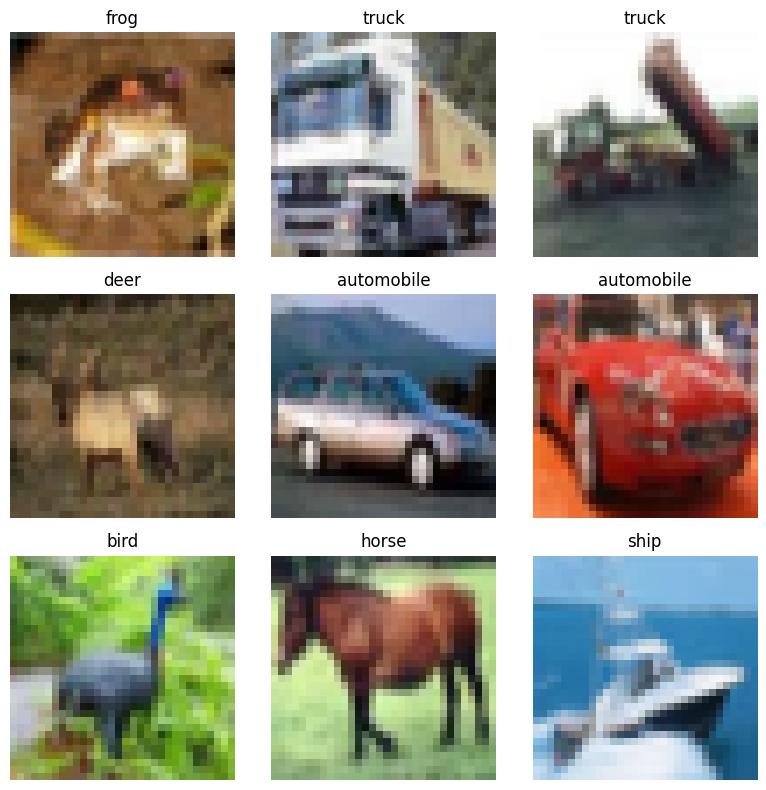

In [5]:
# Visualize a few sample images from the training set
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
print("HARSHAVARTHAN SB 24BAD033")
plt.show()

## Part B: CNN Model Implementation

In [6]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Fully connected layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')   # Softmax output layer, 10 classes
])
print("HARSHAVARTHAN SB 24BAD033")
model.summary()

HARSHAVARTHAN SB 24BAD033


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,986 (1.54 MB)

 Trainable params: 402,986 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the model with the Adam optimizer and cross-entropy loss
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',   # labels are integers, not one-hot
    metrics=['accuracy']
)

## Part C: Model Training and Evaluation

In [8]:
EPOCHS = 15
BATCH_SIZE = 64

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 245s 343ms/step - accuracy: 0.3664 - loss: 1.7149 - val_accuracy: 0.5228 - val_loss: 1.3059
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 267s 350ms/step - accuracy: 0.5508 - loss: 1.2581 - val_accuracy: 0.6364 - val_loss: 1.0062
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 264s 354ms/step - accuracy: 0.6311 - loss: 1.0534 - val_accuracy: 0.6916 - val_loss: 0.8878
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 251s 357ms/step - accuracy: 0.6790 - loss: 0.9198 - val_accuracy: 0.6896 - val_loss: 0.9043
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 263s 359ms/step - accuracy: 0.7137 - loss: 0.8266 - val_accuracy: 0.7156 - val_loss: 0.8475
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 263s 361ms/step - accuracy: 0.7406 - loss: 0.7522 - val_accuracy: 0.7668 - val_loss: 0.6915
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 255s 362ms/step - accuracy: 0.7594 - loss: 0.6911 - val_accuracy: 0.7780 - val_loss: 0.6638
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 258s 356ms/step - accuracy: 0.7803 -

In [9]:
# Evaluate on the test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print("HARSHAVARTHAN SB 24BAD033")
print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

313/313 - 14s - 44ms/step - accuracy: 0.7747 - loss: 0.7820
HARSHAVARTHAN SB 24BAD033

Test Accuracy: 0.7747
Test Loss: 0.7820


In [10]:
# Print final training and validation metrics
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
print("HARSHAVARTHAN SB 24BAD033")
print(f"Final Training Accuracy   : {final_train_acc:.4f}")
print(f"Final Validation Accuracy : {final_val_acc:.4f}")
print(f"Final Training Loss       : {final_train_loss:.4f}")
print(f"Final Validation Loss     : {final_val_loss:.4f}")
print(f"Testing Accuracy          : {test_acc:.4f}")

HARSHAVARTHAN SB 24BAD033
Final Training Accuracy   : 0.8552
Final Validation Accuracy : 0.7838
Final Training Loss       : 0.4009
Final Validation Loss     : 0.7492
Testing Accuracy          : 0.7747


HARSHAVARTHAN SB 24BAD033


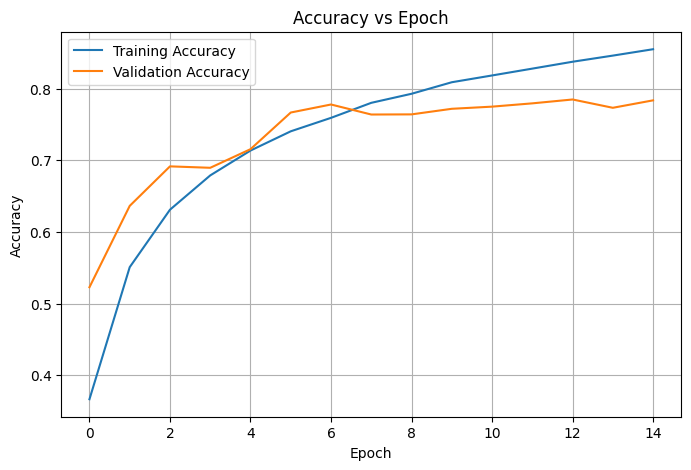

In [11]:
# Plot Accuracy vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
print("HARSHAVARTHAN SB 24BAD033")
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

HARSHAVARTHAN SB 24BAD033


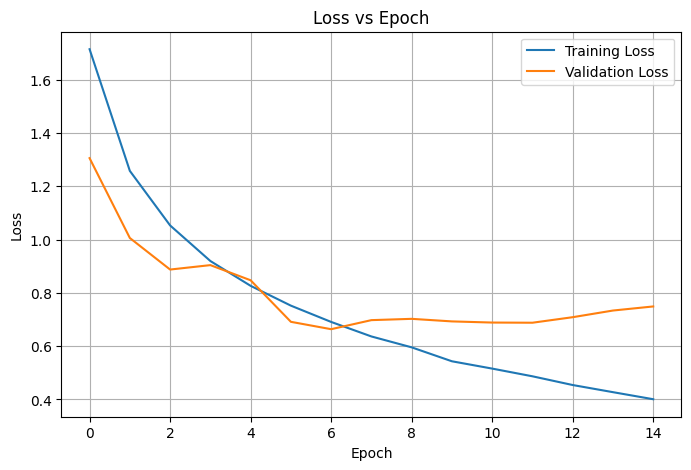

In [12]:
# Plot Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
print("HARSHAVARTHAN SB 24BAD033")
plt.title('Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Part D: Performance Analysis

In [13]:
# Get model predictions on the test set
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification report (precision, recall, f1-score per class)
print("HARSHAVARTHAN SB 24BAD033")
print(classification_report(y_test, y_pred, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step
HARSHAVARTHAN SB 24BAD033
              precision    recall  f1-score   support

    airplane       0.77      0.83      0.80      1000
  automobile       0.93      0.83      0.88      1000
        bird       0.73      0.63      0.68      1000
         cat       0.58      0.62      0.60      1000
        deer       0.74      0.74      0.74      1000
         dog       0.74      0.67      0.71      1000
        frog       0.81      0.82      0.82      1000
       horse       0.75      0.86      0.80      1000
        ship       0.89      0.85      0.87      1000
       truck       0.81      0.90      0.85      1000

    accuracy                           0.77     10000
   macro avg       0.78      0.77      0.77     10000
weighted avg       0.78      0.77      0.77     10000



In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Annotate cell counts
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")
print("HARSHAVARTHAN SB 24BAD033")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

In [ ]:
# Sample predictions: correctly classified images
correct_idx = np.where(y_pred == y_test)[0]

plt.figure(figsize=(10, 10))
for i, idx in enumerate(correct_idx[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}")
    plt.axis('off')
plt.suptitle("Sample Correct Predictions")
print("HARSHAVARTHAN SB 24BAD033")
plt.tight_layout()
plt.show()

Number of misclassified test images: 2253 out of 10000
HARSHAVARTHAN SB 24BAD033


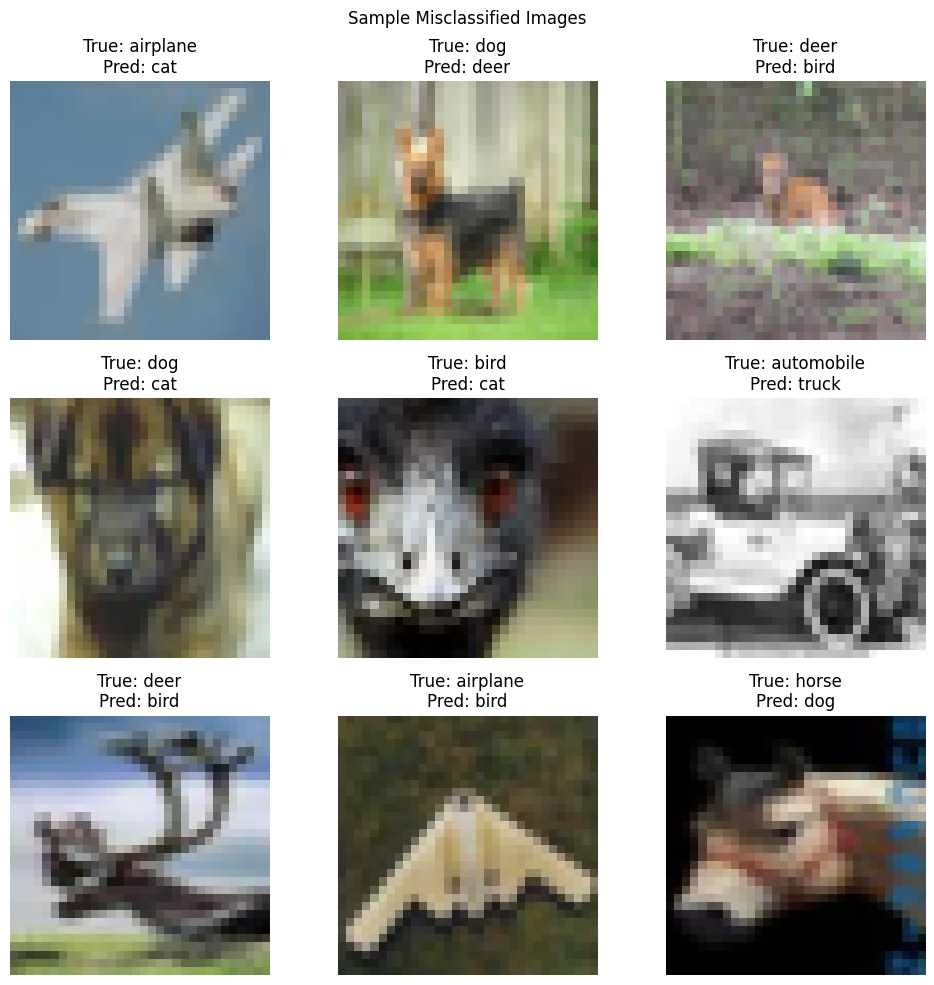

In [16]:
# Misclassified images
misclassified_idx = np.where(y_pred != y_test)[0]
print(f"Number of misclassified test images: {len(misclassified_idx)} out of {len(y_test)}")

plt.figure(figsize=(10, 10))
for i, idx in enumerate(misclassified_idx[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}")
    plt.axis('off')
plt.suptitle("Sample Misclassified Images")
plt.tight_layout()
print("HARSHAVARTHAN SB 24BAD033")
plt.show()